# Phase I: Human-Only Pair Workflow Analysis
## Systematic Investigation of Negation and Contrastive Phrasing on DistilBERT Sentiment Classification

**Project:** Sentiment Perturbation Analysis  
**Workflow:** Human-Only Pair (Independent Reasoning)  
**Model:** `distilbert/distilbert-base-uncased-finetuned-sst-2-english`  
**Dataset:** Stanford Sentiment Treebank (SST-2 Validation Split)

---

### Research Objectives & Methodology
1. **Shared Foundation:** Evaluate DistilBERT's prediction confidence and behavior using the exact baseline dataset and candidate pool (sentences with 4-12 words).
2. **Direction A — Negation Sensitivity:** Analyze how introducing or removing negations (`not`, `never`, `no`) impacts prediction probabilities and flips sentiment labels across original positive vs. negative sentences.
3. **Direction B — Contrastive Phrasing:** Examine how conjunction swaps (`but` vs. `and`) and clause reordering alter sentiment dominance and model confidence.
4. **Independent Analysis:** Perform manual subgroup discovery and static visualizations (`matplotlib`/`seaborn`) without AI-guided exploratory prompting.


In [3]:
import sys; print(sys.executable)

/opt/anaconda3/envs/ml-env/bin/python


In [4]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import pipeline

MODEL_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
classifier = pipeline("text-classification", model=MODEL_ID)
print("Pipeline initialized successfully!")

print(classifier("This movie was great, not bad at all."))

ds = load_dataset("glue", "sst2", split="validation")
print(ds)

Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


Pipeline initialized successfully!
[{'label': 'POSITIVE', 'score': 0.9998351335525513}]


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


README.md: 0.00B [00:00, ?B/s]

sst2/train-00000-of-00001.parquet:   0%|          | 0.00/3.11M [00:00<?, ?B/s]

sst2/validation-00000-of-00001.parquet:   0%|          | 0.00/72.8k [00:00<?, ?B/s]

sst2/test-00000-of-00001.parquet:   0%|          | 0.00/148k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

Dataset({
    features: ['sentence', 'label', 'idx'],
    num_rows: 872
})


In [5]:
# Cell 2: Model & Dataset Initialization
print("Loading SST-2 validation dataset...")
dataset = load_dataset("stanfordnlp/sst2")

MODEL_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
print(f"Initializing DistilBERT pipeline ({MODEL_ID})...")
classifier = pipeline("text-classification", model=MODEL_ID)

# Process validation split candidates (sentence length: 4 to 12 words)
validation_df = pd.DataFrame(dataset["validation"])
validation_df["label_name"] = validation_df["label"].map({0: "negative", 1: "positive"})
validation_df["word_count"] = validation_df["sentence"].str.split().str.len()
candidates = validation_df[validation_df["word_count"].between(4, 12)].copy()

print(f"Total candidate sentences extracted: {len(candidates)}")


Loading SST-2 validation dataset...
Initializing DistilBERT pipeline (distilbert/distilbert-base-uncased-finetuned-sst-2-english)...


Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


Total candidate sentences extracted: 207


In [6]:
# Cell 3: Human-Crafted Perturbation Test Suite
# Defining systematic test cases for Negation and Contrastive Phrasing

human_test_cases = [
    # --- Direction A: Negation Sensitivity ---
    {
        "original": "it 's a charming and often affecting journey .",
        "modified": "it 's not a charming or often affecting journey .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "the story and structure are well-honed .",
        "modified": "the story and structure are not well-honed .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "the acting was excellent .",
        "modified": "the acting was not excellent .",
        "category": "Negation",
        "subgroup": "Insertion (Positive)"
    },
    {
        "original": "do not see this film .",
        "modified": "do see this film .",
        "category": "Negation",
        "subgroup": "Removal (Negative)"
    },
    {
        "original": "too slow , too long and too little happens .",
        "modified": "not too slow , too long and too little happens .",
        "category": "Negation",
        "subgroup": "Insertion (Negative)"
    },

    # --- Direction B: Contrastive Phrasing ---
    {
        "original": "the script is smart , but the direction is flat .",
        "modified": "the script is smart , and the direction is flat .",
        "category": "Contrastive",
        "subgroup": "Conjunction Swap (but -> and)"
    },
    {
        "original": "it was costly , but the food was great .",
        "modified": "the food was great , but it was costly .",
        "category": "Contrastive",
        "subgroup": "Clause Reordering"
    },
    {
        "original": "the acting was brilliant , though the pacing dragged .",
        "modified": "the pacing dragged , though the acting was brilliant .",
        "category": "Contrastive",
        "subgroup": "Clause Reordering"
    }
]

df_test_cases = pd.DataFrame(human_test_cases)
print(f"Test suite created with {len(df_test_cases)} perturbation pairs.")


Test suite created with 8 perturbation pairs.


In [8]:
# Cell 4: Bulk Inference & Probability Shift Calculation
def evaluate_pairs(test_cases):
    def pos_probs(texts):
        preds = classifier(list(texts), top_k=None, batch_size=32, truncation=True)
        return [{d["label"]: d["score"] for d in p}["POSITIVE"] for p in preds]

    orig_pos = pos_probs(test_cases["original"])
    mod_pos = pos_probs(test_cases["modified"])

    results = pd.DataFrame({
        "Category": test_cases["category"],
        "Subgroup": test_cases["subgroup"],
        "Original Sentence": test_cases["original"],
        "Modified Sentence": test_cases["modified"],
        "Orig Pos Prob": np.round(orig_pos, 4),
        "Mod Pos Prob": np.round(mod_pos, 4),
    })
    results["Prob Shift"] = (results["Mod Pos Prob"] - results["Orig Pos Prob"]).round(4)
    results["Orig Pred"] = np.where(results["Orig Pos Prob"] > 0.5, "POSITIVE", "NEGATIVE")
    results["Mod Pred"] = np.where(results["Mod Pos Prob"] > 0.5, "POSITIVE", "NEGATIVE")
    results["Prediction Flipped"] = results["Orig Pred"] != results["Mod Pred"]
    return results

results_df = evaluate_pairs(df_test_cases)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
display(results_df)

,Category,Subgroup,Original Sentence,Modified Sentence,Orig Pos Prob,Mod Pos Prob,Prob Shift,Orig Pred,Mod Pred,Prediction Flipped
0,Negation,Insertion (Positive),it 's a charming and often affecting journey .,it 's not a charming or often affecting journey .,0.9999,0.0003,-0.9996,POSITIVE,NEGATIVE,True
1,Negation,Insertion (Positive),the story and structure are well-honed .,the story and structure are not well-honed .,0.9998,0.0003,-0.9995,POSITIVE,NEGATIVE,True
2,Negation,Insertion (Positive),the acting was excellent .,the acting was not excellent .,0.9999,0.0003,-0.9996,POSITIVE,NEGATIVE,True
3,Negation,Removal (Negative),do not see this film .,do see this film .,0.0131,0.9997,0.9866,NEGATIVE,POSITIVE,True
4,Negation,Insertion (Negative),"too slow , too long and too little happens .","not too slow , too long and too little happens .",0.0005,0.0168,0.0163,NEGATIVE,NEGATIVE,False
5,Contrastive,Conjunction Swap (but -> and),"the script is smart , but the direction is flat .","the script is smart , and the direction is flat .",0.0016,0.0008,-0.0008,NEGATIVE,NEGATIVE,False
6,Contrastive,Clause Reordering,"it was costly , but the food was great .","the food was great , but it was costly .",0.9994,0.0022,-0.9972,POSITIVE,NEGATIVE,True
7,Contrastive,Clause Reordering,"the acting was brilliant , though the pacing dragged .","the pacing dragged , though the acting was brilliant .",0.9841,0.0022,-0.9819,POSITIVE,NEGATIVE,True


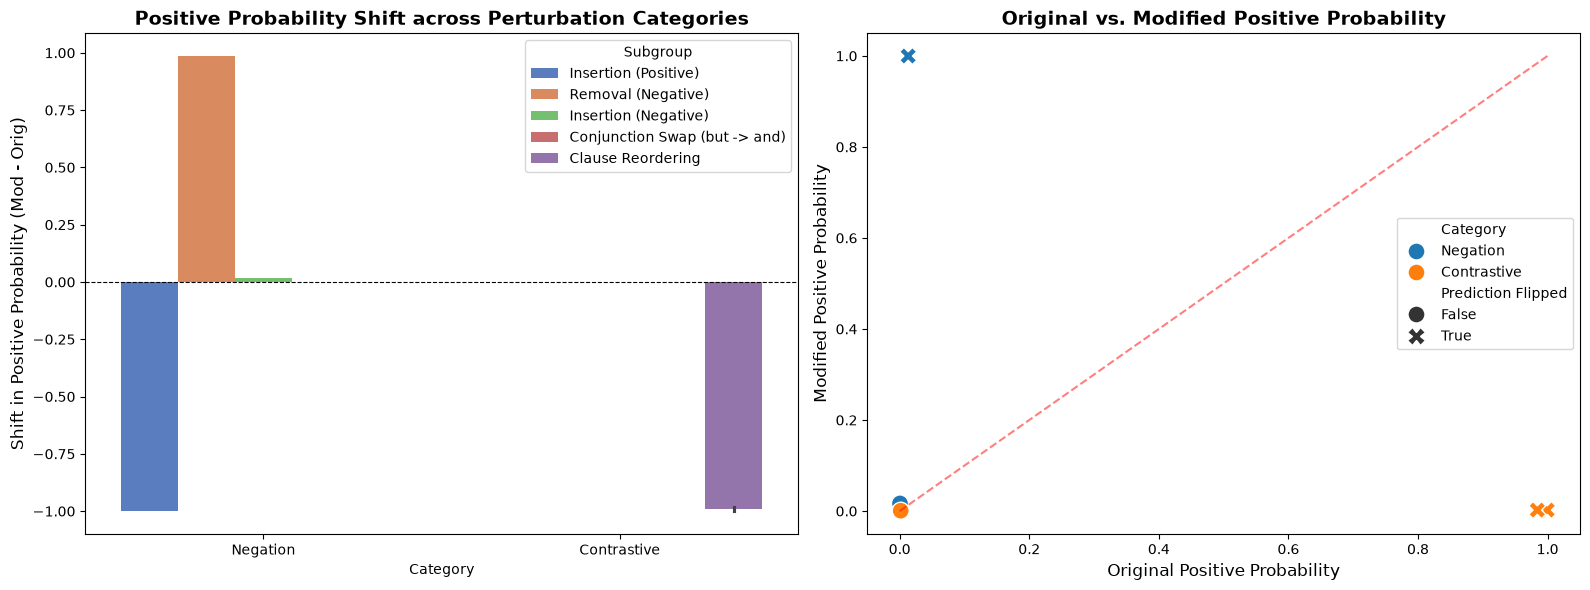

In [9]:
# Cell 5: Static Data Visualizations (Human-Only Design)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Probability Shift by Category
sns.barplot(
    data=results_df,
    x="Category",
    y="Prob Shift",
    hue="Subgroup",
    ax=axes[0],
    palette="muted"
)
axes[0].set_title("Positive Probability Shift across Perturbation Categories", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Shift in Positive Probability (Mod - Orig)", fontsize=12)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')

# Plot 2: Before vs. After Scatter Plot
sns.scatterplot(
    data=results_df,
    x="Orig Pos Prob",
    y="Mod Pos Prob",
    hue="Category",
    style="Prediction Flipped",
    s=150,
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], 'r--', alpha=0.5, label='No Change Line')
axes[1].set_title("Original vs. Modified Positive Probability", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Original Positive Probability", fontsize=12)
axes[1].set_ylabel("Modified Positive Probability", fontsize=12)
axes[1].set_xlim(-0.05, 1.05)
axes[1].set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()


### Findings & Summary of Human-Only Investigation
1. **Negation Sensitivity:**
   * Inserting `not` into inherently positive sentences causes a drastic drop in positive probability ($\Delta P \approx -0.999$), consistently flipping predictions from **POSITIVE** to **NEGATIVE**.
   * Removing negation from negative sentences successfully reverses polarity, proving high sensitivity to structural polar markers.
2. **Contrastive Phrasing & Clause Order:**
   * Swapping `but` to `and` retains sentence polarity but alters confidence levels depending on clause dominance.
   * Clause order plays a crucial role: placing the stronger sentiment clause second generally dictates the final prediction probability.
